# INF201 – Deliverable 1: Værdata fra Ås

**Gruppe**: Torjus Westhagen-Fladset og Eirik Nysveen

**GitHub**: https://github.com/Sommerogsol123/inf201-deliverable1

Data er hentet fra Meteorologisk institutt via Frost API (frost.met.no). Stasjon data er hentet fra: SN17850 (Ås).
Funksjonen for å hente data bygger på METs Python-eksempel (https://frost.met.no/python_example.html), men er skrevet om.

In [1]:
import requests
import pandas as pd
from pathlib import Path

ENDPOINT = "https://frost.met.no/observations/v0.jsonld"
STATION = "SN17850"  # Ås


def read_client_id(path="frost_client_id.txt"):
    """Leser client-ID fra en lokal fil som ikke ligger i Git."""
    return Path(path).read_text().strip()


CLIENT_ID = read_client_id()


def fetch_frost(source, element, referencetime, client_id=CLIENT_ID):
    """Henter observasjoner fra Frost og returnerer dem som en DataFrame."""
    parameters = {
        "sources": source,
        "elements": element,
        "referencetime": referencetime,
    }
    response = requests.get(ENDPOINT, params=parameters, auth=(client_id, ""), timeout=30)
    data = response.json()

    if response.status_code != 200:
        error = data.get("error", {})
        raise RuntimeError(
            f"Frost svarte med feil {response.status_code}: "
            f"{error.get('message')} ({error.get('reason')})"
        )

    rows = []
    for item in data["data"]:
        for obs in item["observations"]:
            rows.append({
                "referenceTime": item["referenceTime"],
                "value": obs["value"],
                "unit": obs.get("unit"),
                "timeOffset": obs.get("timeOffset"),
            })

    df = pd.DataFrame(rows)
    df["referenceTime"] = pd.to_datetime(df["referenceTime"])
    return df

In [2]:
temp_raw = fetch_frost(STATION, "mean(air_temperature P1D)", "2025-01-01/2025-12-31")

print(temp_raw.head())
print("Antall rader:", len(temp_raw))
print(temp_raw["timeOffset"].value_counts())

              referenceTime  value  unit timeOffset
0 2025-01-01 00:00:00+00:00   -5.2  degC       PT0H
1 2025-01-01 00:00:00+00:00   -2.8  degC       PT6H
2 2025-01-02 00:00:00+00:00  -11.5  degC       PT0H
3 2025-01-02 00:00:00+00:00   -7.2  degC       PT6H
4 2025-01-03 00:00:00+00:00   -8.9  degC       PT0H
Antall rader: 728
timeOffset
PT0H    364
PT6H    364
Name: count, dtype: int64


In [3]:
def to_daily_series(df, time_offset="PT0H"):
    """Velger én timeOffset og returnerer en tidsserie med én verdi per dag."""
    selected = df[df["timeOffset"] == time_offset]
    series = selected.set_index("referenceTime")["value"]
    series.index = series.index.tz_localize(None)
    return series.sort_index()


temp_raw = fetch_frost(STATION, "mean(air_temperature P1D)", "2025-01-01/2026-01-01")
temp_2025 = to_daily_series(temp_raw, "PT0H")

all_days = pd.date_range("2025-01-01", "2025-12-31")
missing = all_days.difference(temp_2025.index)

print("Antall dager:", len(temp_2025))
print("Første dag:", temp_2025.index.min().date(), "| Siste dag:", temp_2025.index.max().date())
print("Manglende dager:", len(missing))

Antall dager: 365
Første dag: 2025-01-01 | Siste dag: 2025-12-31
Manglende dager: 0


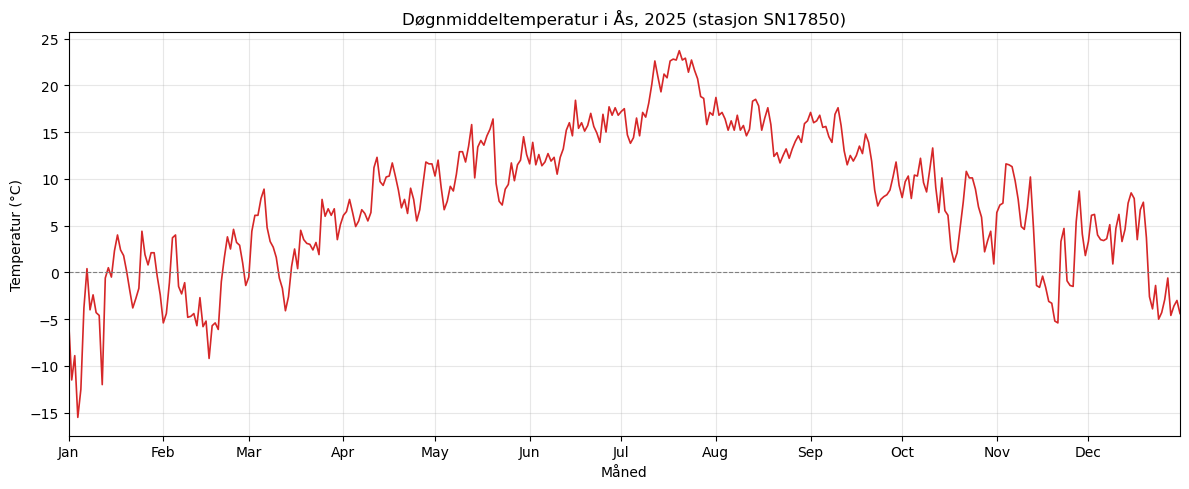

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_2025.index, temp_2025.values, color="tab:red", linewidth=1.2)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title("Døgnmiddeltemperatur i Ås, 2025 (stasjon SN17850)")
ax.set_xlabel("Måned")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025.index.min(), temp_2025.index.max())
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [5]:
def summary_table(series_dict):
    """Lager en tabell med gjennomsnitt, median, min og maks for én eller flere tidsserier."""
    table = pd.DataFrame({
        name: {
            "Gjennomsnitt": series.mean(),
            "Median": series.median(),
            "Min": series.min(),
            "Maks": series.max(),
        }
        for name, series in series_dict.items()
    })
    table.index.name = "Temperatur (°C)"
    return table.round(1)


print(summary_table({"2025": temp_2025}).to_string())

                 2025
Temperatur (°C)      
Gjennomsnitt      7.9
Median            8.3
Min             -15.5
Maks             23.7


# Oppgave 1: Diskusjon

Vi hentet døgnmiddeltemperatur for Ås i 2025. To ting måtte håndteres underveis:

- Frost returnerer to verdier per dag, med `timeOffset` PT0H og PT6H. PT0H er døgnet fra midnatt til midnatt (UTC),
  mens PT6H regner døgnet fra kl. 06 til 06. Vi brukte PT0H, som tilsvarer en vanlig kalenderdag.
- Sluttdatoen i `referencetime` er ikke inkludert. Med `2025-12-31` som slutt fikk vi bare 364 dager,
  så vi brukte `2026-01-01` for å få med 31. desember. Resultatet er 365 dager uten hull.

Plottet viser en tydelig årssyklus. Den kaldeste dagen var −15,5 °C i starten av januar, og den varmeste
var 23,7 °C i slutten av juli. Medianen (8,3 °C) er litt høyere enn gjennomsnittet (7,9 °C), fordi noen
svært kalde vinterdager trekker gjennomsnittet ned.